# TASK 2 — Customer Segmentation Analysis

## Objective
The objective of this project is to group customers into different segments using the K-Means clustering algorithm. This helps identify patterns in customer characteristics and supports targeted marketing strategies.

## Tools and Technologies
- Python
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Overview
In this project, I will inspect and clean the customer dataset, select relevant features, standardize the data, and apply K-Means clustering. I will use the Elbow Method to help determine the number of clusters, visualize the results, and analyze the characteristics of each customer group.

The available dataset contains demographic information and spending scores. Since transaction-level purchase data is not available, the analysis will focus on customer characteristics rather than traditional RFM analysis.

## 1. Load and Inspect the Dataset

The first step is to load the customer dataset using Pandas and understand its structure. I will check the number of rows and columns, examine the column names and data types, identify missing values, and check for duplicate records. This helps determine what cleaning is required before performing the clustering analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Test.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (2627, 11)


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,B
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,A
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6,A
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,B
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6,A


<class 'pandas.DataFrame'>
RangeIndex: 2627 entries, 0 to 2626
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2627 non-null   int64  
 1   Gender           2627 non-null   str    
 2   Ever_Married     2577 non-null   str    
 3   Age              2627 non-null   int64  
 4   Graduated        2603 non-null   str    
 5   Profession       2589 non-null   str    
 6   Work_Experience  2358 non-null   float64
 7   Spending_Score   2627 non-null   str    
 8   Family_Size      2514 non-null   float64
 9   Var_1            2595 non-null   str    
 10  Segmentation     2627 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 225.9 KB


In [2]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Fill missing categorical values with the mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if col != "Segmentation":
        df[col] = df[col].fillna(df[col].mode()[0])

# Fill missing numerical values with the median
numeric_cols = ["Work_Experience", "Family_Size"]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Remaining missing values:", df.isnull().sum().sum())

ID                   0
Gender               0
Ever_Married        50
Age                  0
Graduated           24
Profession          38
Work_Experience    269
Spending_Score       0
Family_Size        113
Var_1               32
Segmentation         0
dtype: int64
Duplicate rows: 0
Remaining missing values: 0


C:\Users\ATUL\AppData\Local\Temp\ipykernel_23288\2932958980.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


### Dataset Inspection — Observations

The dataset contains customer demographic details, work experience, family size, spending scores, and a pre-existing segmentation label. The dataset was inspected for missing values, data types, and duplicate records. Missing values in relevant columns were handled before proceeding with feature selection and clustering.

The existing `Segmentation` column is kept separate from the K-Means input features so that it does not influence the clustering results.

In [3]:
features = df[[
    "Age",
    "Work_Experience",
    "Family_Size",
    "Spending_Score"
]].copy()

features["Spending_Score"] = features["Spending_Score"].map({
    "Low": 0,
    "Average": 1,
    "High": 2
})

display(features.head())

,Age,Work_Experience,Family_Size,Spending_Score
0,36,0.0,1.0,0
1,37,8.0,4.0,1
2,69,0.0,1.0,0
3,59,11.0,2.0,2
4,19,1.0,4.0,0


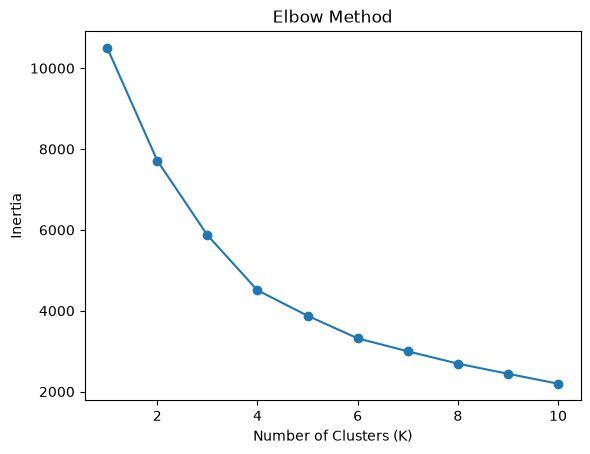

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.show()

In [10]:
average_age = df["Age"].mean()

average_work_experience = df["Work_Experience"].mean()

average_family_size = df["Family_Size"].mean()

most_common_spending_score = df["Spending_Score"].mode()[0]

spending_distribution = df["Spending_Score"].value_counts()

print("Average Customer Age:", round(average_age, 2))
print("Average Work Experience:", round(average_work_experience, 2))
print("Average Family Size:", round(average_family_size, 2))
print("Most Common Spending Score:", most_common_spending_score)

print("\nCustomer Spending Score Distribution:")
display(spending_distribution)

Average Customer Age: 43.65
Average Work Experience: 2.39
Average Family Size: 2.79
Most Common Spending Score: Low

Customer Spending Score Distribution:


Spending_Score
Low        1616
Average     625
High        386
Name: count, dtype: int64

### Descriptive Statistics — Observations

Descriptive statistics summarize the characteristics of customers in the dataset. Average age, work experience, and family size help describe the customer base. The spending score distribution shows how customers are classified as Low, Average, or High spenders.

Average purchase value, purchase frequency, and customer lifetime value cannot be calculated directly because the dataset does not include transaction amounts, order IDs, or purchase dates. Therefore, the available customer characteristics and spending scores will be used for the clustering analysis.

In [11]:
features = df[[
    "Age",
    "Work_Experience",
    "Family_Size"
]].copy()

print("Selected Features:")
display(features.head())

print("\nFeature Names:")
print(features.columns.tolist())

Selected Features:


,Age,Work_Experience,Family_Size
0,36,0.0,1.0
1,37,8.0,4.0
2,69,0.0,1.0
3,59,11.0,2.0
4,19,1.0,4.0



Feature Names:
['Age', 'Work_Experience', 'Family_Size']


### Feature Selection — Observations

Three numerical features, Age, Work Experience, and Family Size, were selected for customer segmentation. These features help identify groups of customers with similar characteristics. Since the dataset does not contain transaction history or purchase amounts, traditional RFM analysis cannot be performed. The selected features will be standardized before applying the K-Means clustering algorithm.

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

scaled_features = pd.DataFrame(
    X_scaled,
    columns=features.columns
)

print("Standardized Features:")
display(scaled_features.head())

Standardized Features:


,Age,Work_Experience,Family_Size
0,-0.450948,-0.748105,-1.172097
1,-0.391999,1.752242,0.792450
2,1.494372,-0.748105,-1.172097
3,0.904881,2.689872,-0.517248
4,-1.453083,-0.435562,0.792450


### Data Standardization — Observations

The selected features were standardized using StandardScaler. This transforms the features to have a mean close to zero and a standard deviation close to one. Standardization ensures that differences in numerical scales have less influence on the K-Means clustering results. The standardized data is now ready for clustering.

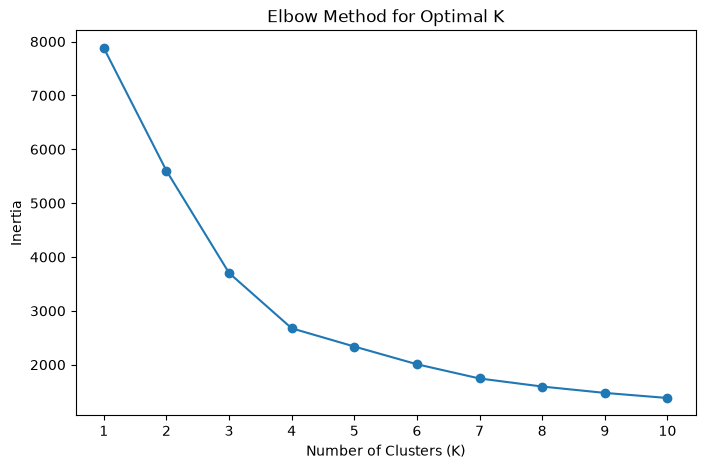

In [14]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
inertia = []    
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.show()

In [15]:
optimal_k = 4  

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("Number of clusters:", optimal_k)

display(df[["ID", "Age", "Work_Experience",
            "Family_Size", "Cluster"]].head())


K-Means clustering completed!
Number of clusters: 4


,ID,Age,Work_Experience,Family_Size,Cluster
0,458989,36,0.0,1.0,1
1,458994,37,8.0,4.0,2
2,458996,69,0.0,1.0,0
3,459000,59,11.0,2.0,2
4,459001,19,1.0,4.0,3


### K-Means Clustering — Observations

The Elbow Method was used to compare different numbers of clusters by examining their inertia values. Based on the graph, a suitable number of clusters was selected, and the K-Means algorithm assigned each customer to a cluster based on Age, Work Experience, and Family Size. These groups will be analyzed further to understand their characteristics.

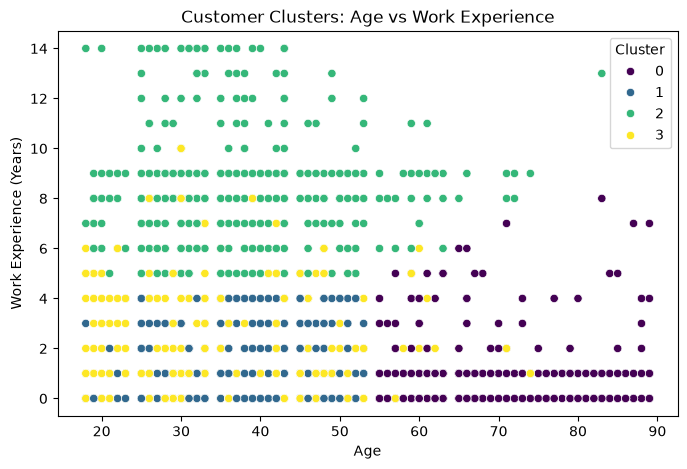

In [16]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Work_Experience",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Clusters: Age vs Work Experience")
plt.xlabel("Age")
plt.ylabel("Work Experience (Years)")
plt.show()


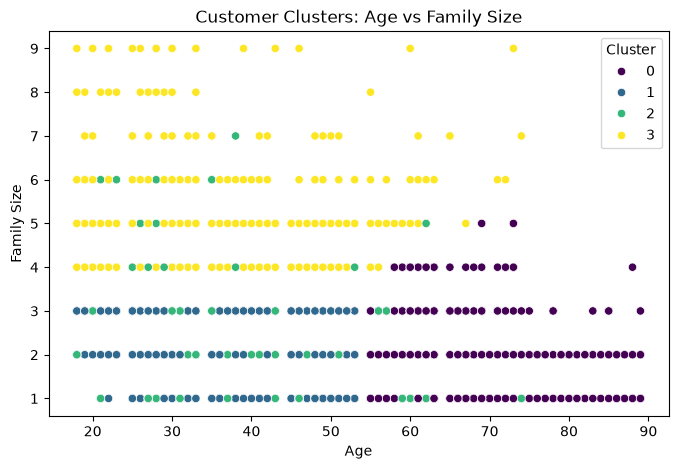

In [17]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Family_Size",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Clusters: Age vs Family Size")
plt.xlabel("Age")
plt.ylabel("Family Size")
plt.show()



### Cluster Visualization — Observations

The scatter plots visualize the customer groups identified by K-Means clustering. The first plot compares age with work experience, while the second compares age with family size. The different colors help show how customers are distributed across the clusters. Some overlap may occur because the clusters are formed using all three selected features.

In [18]:
cluster_profile = df.groupby("Cluster").agg(
    Customer_Count=("ID", "count"),
    Average_Age=("Age", "mean"),
    Average_Work_Experience=("Work_Experience", "mean"),
    Average_Family_Size=("Family_Size", "mean")
).round(2)

display(cluster_profile)


,Customer_Count,Average_Age,Average_Work_Experience,Average_Family_Size
Cluster,,,,
0,552,69.46,0.88,2.07
1,945,37.56,0.95,2.06
2,491,37.25,8.32,2.37
3,639,35.27,1.27,4.82


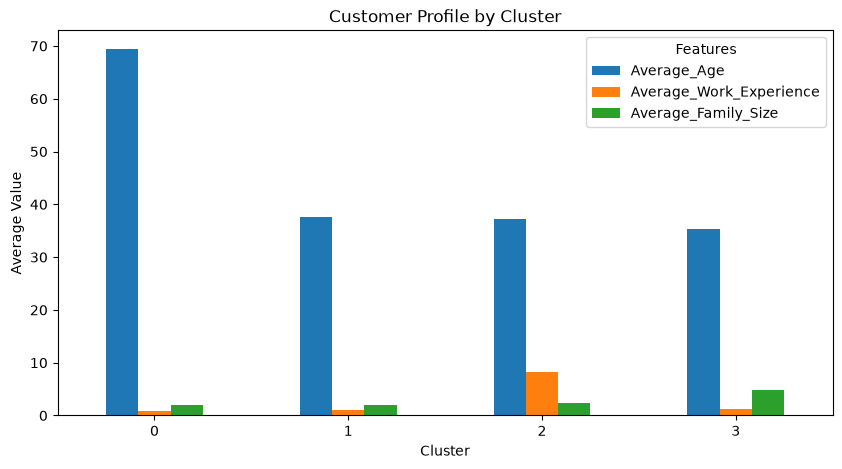

In [19]:
cluster_profile[
    ["Average_Age", "Average_Work_Experience", "Average_Family_Size"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Customer Profile by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Features")
plt.show()

### Cluster Profiling — Observations

The cluster profile summarizes the number of customers, average age, average work experience, and average family size for each cluster. These values help identify similarities and differences between the groups. Based on the calculated averages, each cluster can be described according to its main demographic characteristics.

Number of Customers in Each Cluster:


Cluster
0    552
1    945
2    491
3    639
Name: count, dtype: int64

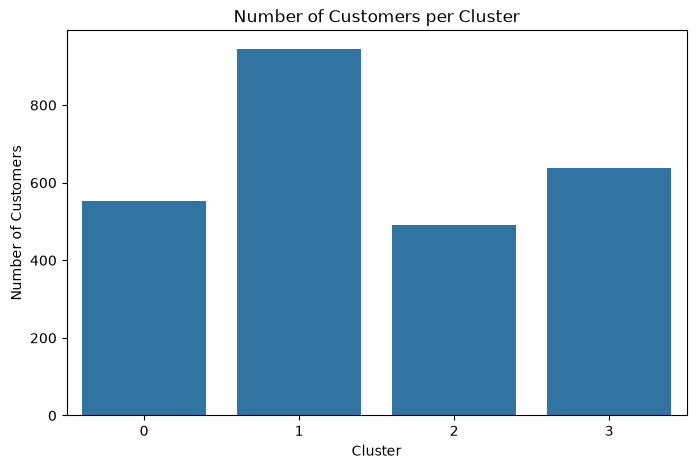

In [20]:
cluster_counts = df["Cluster"].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
display(cluster_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

### Customer Distribution — Observations

The bar chart shows the number of customers assigned to each cluster by the K-Means algorithm. It helps identify the largest and smallest customer groups. This information can help a business decide how to allocate its marketing resources across different customer segments.

### Insights and Marketing Recommendations

K-Means clustering groups customers with similar demographic characteristics. Businesses can use these groups to plan more relevant marketing campaigns.

1. **Younger customers:** Test digital campaigns and promotions suited to their interests.
2. **Older customers:** Provide relevant product information and personalized offers.
3. **Larger households:** Test family bundles and multi-item discounts.
4. **Smaller households:** Promote individual products and smaller product packages.

These recommendations should be evaluated using campaign results. Since the dataset lacks transaction history and purchase amounts, the clusters should not be interpreted as confirmed high-value or low-value customer segments.